# 02 - Silver Merge and EDA

**Layer:** Silver (merged and cleaned data)

## Goal
Merge the 20 raw files into one master dataset, add `city` and `day_type`
extracted from the file names, and drop the leftover index column.

## Step 1: Setup
Ask for the bronze and silver folder paths and create the silver folder if needed.

In [9]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
default_bronze = "../data/bronze/csv"
default_silver = "../data/silver"
    
bronze_path = input(f"Enter bronze folder path [{default_bronze}]: ").strip()
if bronze_path == "":
    bronze_path = default_bronze

silver_path = input(f"Enter silver folder path [{default_silver}]: ").strip()
if silver_path == "":
    silver_path = default_silver

# Create the silver folder if it does not exist
os.makedirs(silver_path, exist_ok=True)

# Collect and sort the CSV files
all_files = os.listdir(bronze_path)
csv_files = []
i = 0
while i < len(all_files):
    if all_files[i].lower().endswith(".csv"):
        csv_files.append(all_files[i])
    i += 1
csv_files.sort()
print(f"Found {len(csv_files)} CSV files")

Found 20 CSV files


## Step 2: Load, Tag, and Append
For each file: read it, extract `city` and `day_type` from the file name
(pattern: `{city}_{weekdays|weekends}.csv`), drop `Unnamed: 0`, and collect it.

In [2]:
frames = []
expected_rows = 0

i = 0
while i < len(csv_files):
    file_name = csv_files[i]
    df = pd.read_csv(os.path.join(bronze_path, file_name))
    expected_rows += len(df)

    # Extract city and day type from the file name
    name_parts = file_name[:-4].split("_")
    city = name_parts[0].capitalize()
    day_type = "weekday" if name_parts[1] == "weekdays" else "weekend"

    df["city"] = city
    df["day_type"] = day_type

    # Drop the leftover index column if it exists
    if "Unnamed: 0" in df.columns:
        df = df.drop(columns=["Unnamed: 0"])

    frames.append(df)
    i += 1

master = pd.concat(frames, ignore_index=True)
print("Master shape:", master.shape)

Master shape: (51707, 21)


## Step 3: Validation
Check that no rows were lost, and that every city/day_type combination is present.

In [3]:
# Row count must match the sum of all files
print("Expected rows:", expected_rows)
print("Actual rows  :", len(master))
print("Row count matches:", expected_rows == len(master))

# Rows per city and day type
display(pd.crosstab(master["city"], master["day_type"]))

# Duplicates and nulls on the merged data
print("Duplicated rows:", master.duplicated().sum())
print("Total nulls:", master.isnull().sum().sum())

Expected rows: 51707
Actual rows  : 51707
Row count matches: True


day_type,weekday,weekend
city,,
Amsterdam,1103,977
Athens,2653,2627
Barcelona,1555,1278
Berlin,1284,1200
Budapest,2074,1948
Lisbon,2857,2906
London,4614,5379
Paris,3130,3558
Rome,4492,4535


Duplicated rows: 0
Total nulls: 0


## Step 4: Save the Merged Dataset
Save the merged data to the silver layer.

In [4]:
output_file = os.path.join(silver_path, "airbnb_merged.csv")
master.to_csv(output_file, index=False)
print("Saved:", output_file)

Saved: ../data/silver\airbnb_merged.csv


## Step 5: Price Distribution and Outliers
Inspect the target column `realSum` (price). Prices are usually right-skewed,
so a log version is created for analysis. Outliers are counted per city using
the IQR rule, but nothing is removed yet.

count    51707.000000
mean       279.879591
std        327.948386
min         34.779339
25%        148.752174
50%        211.343089
75%        319.694287
max      18545.450285
Name: realSum, dtype: float64
Skewness: 21.42


,city,median_price,max_price,upper_bound,outliers,outliers_pct
0,Amsterdam,460.2,8130.7,1218.4,105,5.05
1,Athens,127.7,18545.5,280.9,293,5.55
2,Barcelona,208.3,6943.7,583.2,227,8.01
3,Berlin,191.2,5857.5,478.5,165,6.64
4,Budapest,153.0,3751.2,308.0,223,5.54
5,Lisbon,225.4,1681.1,475.6,192,3.33
6,London,261.3,15499.9,841.0,531,5.31
7,Paris,317.6,16445.6,793.8,386,5.77
8,Rome,182.6,2418.3,394.4,433,4.80
9,Vienna,208.5,13664.3,440.0,151,4.27


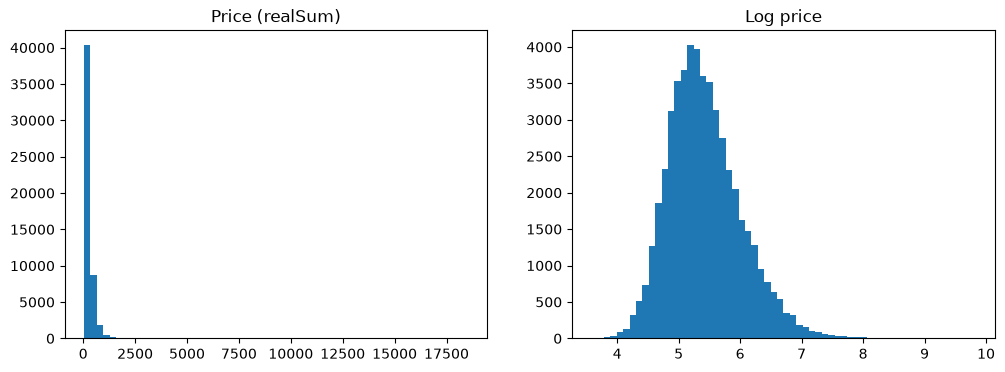

In [10]:
import matplotlib.pyplot as plt

print(master["realSum"].describe())
print("Skewness:", round(master["realSum"].skew(), 2))

# Log price is used for analysis only (reduces the effect of extreme values)
master["log_price"] = np.log1p(master["realSum"])

# Count outliers per city using the IQR rule
cities = sorted(master["city"].unique())
outlier_rows = []

i = 0
while i < len(cities):
    prices = master[master["city"] == cities[i]]["realSum"]
    q1 = prices.quantile(0.25)
    q3 = prices.quantile(0.75)
    upper_bound = q3 + 1.5 * (q3 - q1)
    outlier_count = int((prices > upper_bound).sum())

    outlier_rows.append({
        "city": cities[i],
        "median_price": round(prices.median(), 1),
        "max_price": round(prices.max(), 1),
        "upper_bound": round(upper_bound, 1),
        "outliers": outlier_count,
        "outliers_pct": round(outlier_count / len(prices) * 100, 2),
    })
    i += 1

display(pd.DataFrame(outlier_rows))

# Raw vs log price distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(master["realSum"], bins=60)
axes[0].set_title("Price (realSum)")
axes[1].hist(master["log_price"], bins=60)
axes[1].set_title("Log price")
plt.show()

## Step 6: Correlation with Price
Boolean columns are converted to 0/1 so they can be included.
Both Pearson (linear) and Spearman (rank-based) correlations are computed,
because price is skewed and Spearman is more robust.

,pearson,spearman
attr_index_norm,0.292,0.494
attr_index,0.178,0.385
lat,0.212,0.357
lng,-0.174,-0.352
room_private,-0.172,-0.334
rest_index,0.135,0.333
rest_index_norm,0.144,0.310
person_capacity,0.203,0.295
bedrooms,0.222,0.226
metro_dist,-0.061,-0.133


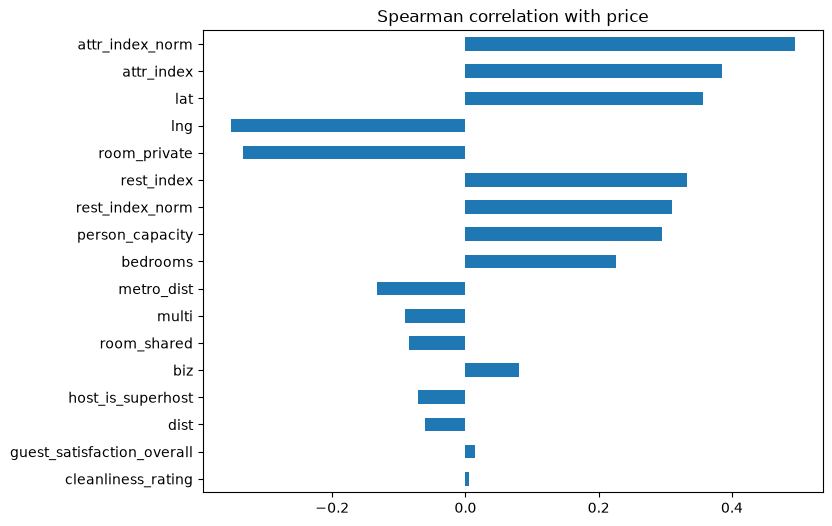

In [11]:
numeric_df = master.copy()

# Convert boolean columns to integers
bool_cols = ["room_shared", "room_private", "host_is_superhost"]
i = 0
while i < len(bool_cols):
    numeric_df[bool_cols[i]] = numeric_df[bool_cols[i]].astype(int)
    i += 1

num_cols = list(numeric_df.select_dtypes(include="number").columns)

pearson = numeric_df[num_cols].corr(method="pearson")["realSum"]
spearman = numeric_df[num_cols].corr(method="spearman")["realSum"]

corr_df = pd.DataFrame({"pearson": pearson, "spearman": spearman})
corr_df = corr_df.drop(index=["realSum", "log_price"]).round(3)
corr_df = corr_df.reindex(corr_df["spearman"].abs().sort_values(ascending=False).index)
display(corr_df)

# Bar chart of Spearman correlation
corr_df["spearman"].plot(kind="barh", figsize=(8, 6), title="Spearman correlation with price")
plt.gca().invert_yaxis()
plt.show()

## Step 7: Price by Category
Compare the median price across cities, day types, and room types.

In [12]:
display(master.groupby("city")["realSum"].median().sort_values(ascending=False).round(1))
display(master.groupby("day_type")["realSum"].median().round(1))
display(master.groupby("room_type")["realSum"].median().round(1))

city
Amsterdam    460.2
Paris        317.6
London       261.3
Lisbon       225.4
Vienna       208.5
Barcelona    208.3
Berlin       191.2
Rome         182.6
Budapest     153.0
Athens       127.7
Name: realSum, dtype: float64

day_type
weekday    207.1
weekend    216.5
Name: realSum, dtype: float64

room_type
Entire home/apt    248.5
Private room       166.4
Shared room        124.5
Name: realSum, dtype: float64

## Step 8: Baseline Model (Is Extra Data Needed?)
Single-feature correlations can look weak even when features together explain
price well. A quick Random Forest on the existing features gives a more honest
answer: if R2 is high, extra scraped features may not be necessary.

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

# Drop the target, its log version, and columns that duplicate other columns
drop_cols = ["realSum", "log_price", "room_shared", "room_private",
             "attr_index_norm", "rest_index_norm"]
X = pd.get_dummies(master.drop(columns=drop_cols), drop_first=True)
y = master["log_price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)
print("R2 on test set (log price):", round(r2_score(y_test, model.predict(X_test)), 3))

importances = pd.Series(model.feature_importances_, index=X.columns)
display(importances.sort_values(ascending=False).head(10).round(3))

R2 on test set (log price): 0.863


lng                           0.227
room_type_Private room        0.183
lat                           0.151
attr_index                    0.080
bedrooms                      0.072
rest_index                    0.060
dist                          0.052
person_capacity               0.046
metro_dist                    0.039
guest_satisfaction_overall    0.032
dtype: float64

## Step 9: Correlation Within Each City
The global correlation mixes city effects with feature effects.
Computing Spearman correlation inside each city shows which features
actually explain price differences between listings of the same city.

In [19]:
feature_cols = ["person_capacity", "bedrooms", "dist", "metro_dist",
                "attr_index_norm", "rest_index_norm", "cleanliness_rating",
                "guest_satisfaction_overall", "multi", "biz"]

city_corr = {}
cities = sorted(master["city"].unique())

i = 0
while i < len(cities):
    city_df = master[master["city"] == cities[i]]
    values = []
    j = 0
    while j < len(feature_cols):
        values.append(city_df["realSum"].corr(city_df[feature_cols[j]], method="spearman"))
        j += 1
    city_corr[cities[i]] = values
    i += 1

within_city_df = pd.DataFrame(city_corr, index=feature_cols).round(2)
within_city_df["mean"] = within_city_df.mean(axis=1).round(2)
within_city_df.sort_values("mean", ascending=False)

,Amsterdam,Athens,Barcelona,Berlin,Budapest,Lisbon,London,Paris,Rome,Vienna,mean
person_capacity,0.61,0.41,0.57,0.38,0.39,0.64,0.60,0.52,0.52,0.48,0.51
attr_index_norm,0.41,0.48,0.28,0.38,0.29,0.29,0.43,0.46,0.52,0.30,0.38
bedrooms,0.54,0.29,0.42,0.23,0.29,0.46,0.36,0.35,0.36,0.27,0.36
rest_index_norm,0.42,0.29,0.29,0.39,0.24,0.28,0.45,0.37,0.52,0.31,0.36
biz,0.02,0.27,0.40,0.20,0.11,-0.03,0.18,0.19,0.07,0.22,0.16
guest_satisfaction_overall,0.18,0.19,0.09,0.04,0.10,0.19,0.00,0.08,0.11,0.10,0.11
cleanliness_rating,0.02,0.19,0.11,0.06,0.07,0.17,0.05,0.09,0.05,0.18,0.10
multi,-0.20,-0.10,-0.21,0.06,-0.11,-0.07,-0.08,0.01,-0.09,-0.07,-0.09
metro_dist,-0.19,-0.16,-0.09,-0.25,-0.15,0.08,-0.35,-0.05,0.10,-0.16,-0.12
dist,-0.39,-0.44,-0.28,-0.29,-0.25,-0.28,-0.42,-0.23,-0.22,-0.33,-0.31


## Step 10: Inspect Extreme Prices
Look at the most expensive listings before deciding how to treat outliers.
Nothing is removed here; the goal is to see whether they look like real
listings or data errors.

In [20]:
cols_to_show = ["city", "day_type", "room_type", "person_capacity",
                "bedrooms", "multi", "biz", "realSum"]
display(master.sort_values("realSum", ascending=False)[cols_to_show].head(20))

# How many listings are above common thresholds?
thresholds = [1000, 2000, 5000]
i = 0
while i < len(thresholds):
    count = int((master["realSum"] > thresholds[i]).sum())
    print(f"Listings above {thresholds[i]}: {count}")
    i += 1

,city,day_type,room_type,person_capacity,bedrooms,multi,biz,realSum
3590,Athens,weekday,Entire home/apt,2.0,1,0,1,18545.450285
34803,Paris,weekday,Entire home/apt,2.0,1,0,0,16445.614689
24348,London,weekday,Entire home/apt,3.0,3,0,1,15499.894165
48380,Vienna,weekday,Private room,2.0,1,0,0,13664.305916
50787,Vienna,weekend,Private room,2.0,1,0,0,13656.358834
48215,Vienna,weekday,Entire home/apt,4.0,1,0,1,12942.991375
30626,London,weekend,Entire home/apt,6.0,2,0,0,12937.275101
31635,London,weekend,Private room,2.0,1,0,0,12929.513864
25945,London,weekday,Private room,2.0,1,0,0,12886.239093
25629,London,weekday,Entire home/apt,6.0,2,0,0,12886.239093


Listings above 1000: 771
Listings above 2000: 136
Listings above 5000: 26


## EDA Findings
- Price distribution: heavily right-skewed (skewness 21.4); median 211, mean 280, max 18,545
- Outliers: about 3-8% per city by IQR rule; extreme cases in Athens, Paris, London, Vienna need review
- Strongest correlations (Spearman): attr_index_norm (0.49), attr_index (0.39), lat (0.36), lng (-0.35)
- Weak or no relation: cleanliness_rating, guest_satisfaction_overall, dist
- Price by city (median): Amsterdam 460 > Paris 318 > London 261 ... Athens 128
- Price by room type (median): Entire home 248.5 > Private 166.4 > Shared 124.5
- Weekday vs weekend: small difference (207 vs 216.5)
- Baseline Random Forest R2 (log price): 0.863